# Assignment 8: Matplotlib & Seaborn: Representation of Women in STEM Education 
## Introduction
This assignment uses the dataset "Women’s Representation in Global STEM Education", which can be found on [Kaggle](https://www.kaggle.com/datasets/bismasajjad/womens-representation-in-global-stem-education/data) to explore, compare and contrast the Matplotlib and Seaborn Python libraries for data visualization. It has data covering the enrollment of women in STEM programs from different countries, and within different years between 2000 and 2023. I chose this dataset because I am a woman who is pursuing an education in a STEM field. I would like to learn more about how the enrollment of women in STEM fields varies by country, and whether or not it has changed over the years that this data was collected.

## Data Exploration

In [ ]:
#load data and necessary libraries 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
stem = pd.read_csv('women_in_stem.csv')

### Summary Statistics

In [5]:
#retrieve the first 5 rows of the data
print(stem.head())
#summary statistics for all columnns 
print(stem.describe(include='all'))

   Country  Year  Female Enrollment (%)  Female Graduation Rate (%)  \
0    China  2018                   20.4                        43.2   
1    China  2005                   35.6                        29.3   
2    China  2005                   53.7                        32.4   
3  Germany  2007                   65.0                        63.6   
4   Canada  2010                   54.4                        28.8   

   STEM Fields  Gender Gap Index  
0  Engineering              0.52  
1  Mathematics              0.98  
2      Biology              0.60  
3  Mathematics              0.69  
4  Engineering              0.74  
       Country         Year  Female Enrollment (%)  \
count      500   500.000000             500.000000   
unique       6          NaN                    NaN   
top      China          NaN                    NaN   
freq        88          NaN                    NaN   
mean       NaN  2011.418000              43.939800   
std        NaN     7.187112            

The above summary statistics tell us that this dataset includes data from 6 different countries and 4 different STEM fields. The earliest year that the data includes in 2000, and the latest is 2023. The mean percentage of female students enrolled in the STEM field across all countries and years is 43.94%, while the mean graduation rate is 36.72%, and the mean gender gap index is 0.75. A gender gap index of 1 indicates gender equality between men and women in a given STEM field, country and year.

### Missing Value Information 

In [6]:
#percentage of missing values in each column 
print(stem.isna().mean() * 100)

Country                       0.0
Year                          0.0
Female Enrollment (%)         0.0
Female Graduation Rate (%)    0.0
STEM Fields                   0.0
Gender Gap Index              0.0
dtype: float64


There are no missing values in this data. 

### Column Data Types

In [8]:
#column data types
print(stem.dtypes)
#

Country                           str
Year                            int64
Female Enrollment (%)         float64
Female Graduation Rate (%)    float64
STEM Fields                       str
Gender Gap Index              float64
dtype: object


## Data Wrangling

Since the above data exploration showed us that the columns are already pretty tidy, there are only a few changes that might be made to the stem dataset in order to make it more readable and usable. 

In [34]:
#changing the year column data type from int64 to datetime
stem['Year'] = pd.to_datetime(stem['Year'], format='%Y')

In [35]:
print(stem.dtypes)

Country                                  str
Year                          datetime64[us]
Female Enrollment (%)                float64
Female Graduation Rate (%)           float64
STEM Fields                              str
Gender Gap Index                     float64
dtype: object


In [36]:
#additionally, the data can be sorted by country and year so that each country's information is more easily accessible
stem = stem.sort_values(by=['Country', 'Year'])
print(stem.head())

       Country       Year  Female Enrollment (%)  Female Graduation Rate (%)  \
12   Australia 2000-01-01                   68.0                        31.3   
99   Australia 2000-01-01                   55.0                        43.1   
102  Australia 2000-01-01                   68.2                        62.5   
237  Australia 2000-01-01                   25.3                        41.7   
339  Australia 2000-01-01                   50.8                        27.6   

          STEM Fields  Gender Gap Index  
12        Engineering              0.51  
99        Mathematics              0.98  
102           Biology              0.99  
237  Computer Science              0.97  
339       Mathematics              0.76  


## Visualizations 


### Part 1: Matplotlib

Below is a bar chart that assesses which countries have the smallest and largest gender gap indexes in STEM.

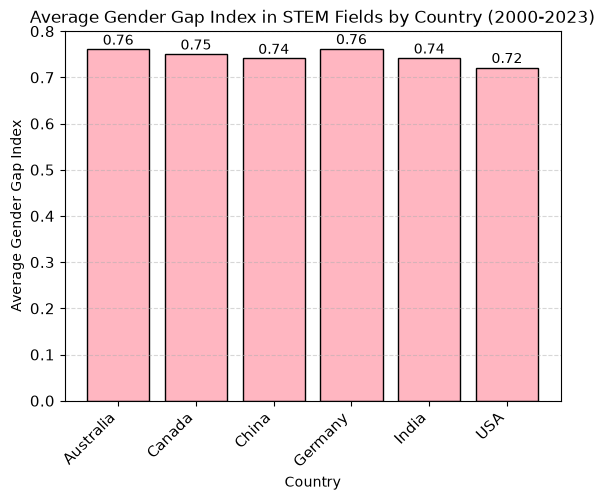

In [53]:
#calculate average gender gap index in each country
gender_gap_avg = stem.groupby('Country')['Gender Gap Index'].mean()
#gender gap index by country bar chart
plt.bar(gender_gap_avg.index, gender_gap_avg.values,
        color='lightpink', edgecolor='black') 
#change title & x/y labs
plt.title('Average Gender Gap Index in STEM Fields by Country (2000-2023)')
plt.xlabel('Country')
plt.ylabel('Average Gender Gap Index')
#modify axis text ticks/ labels
plt.xticks(rotation=45, ha='right')
#change size of axis labels
plt.tick_params(axis='both', labelsize=11)
#add annotations
for i, v in enumerate(gender_gap_avg.values):
    plt.text(i, v + 0.01, round(v, 2), ha='center')
#add lines for y axis on grid
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

The following scatter plot compares female enrollment and graduation rates by each STEM field in the dataset.

Text(0, 0.5, 'Female Graduation Rate (%)')

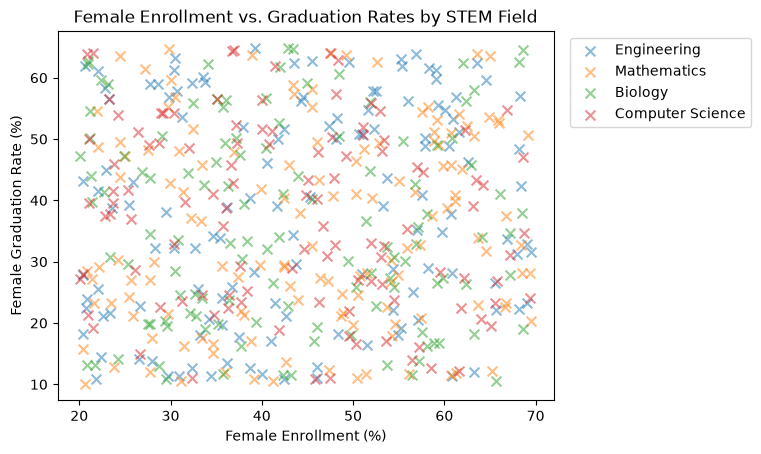

In [ ]:
#loop through stem fields column to get indiviudal field names
for field in stem['STEM Fields'].unique():
    field_column_data = stem[stem['STEM Fields'] == field]
#create scatter plot
    plt.scatter(field_column_data['Female Enrollment (%)'],
                field_column_data['Female Graduation Rate (%)'],
                label=field,
                marker="x",
                s=50,
                alpha=0.5)
#change legend font size 
plt.legend(fontsize=10)
#place legend outside of plot
plt.legend(bbox_to_anchor=(1.02, 1))
#change title & x/y labs
plt.title('Female Enrollment vs. Graduation Rates by STEM Field')
plt.xlabel('Female Enrollment (%)')
plt.ylabel('Female Graduation Rate (%)')
plt.show()

### Part 2: Seaborn

The above bar chart recreated by the seaborn library:

/var/folders/pj/drdj6l3n4z91syrscyd0tcz00000gn/T/ipykernel_15794/3163631767.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


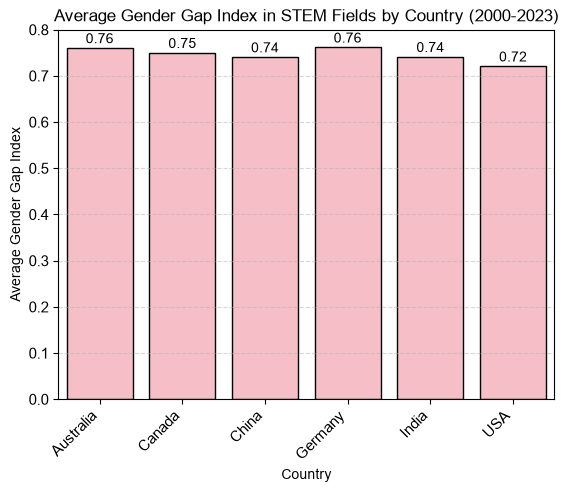

In [74]:
#calculate average gender gap index in each country
gender_gap_avg = stem.groupby('Country')['Gender Gap Index'].mean().reset_index()
#create bar chart
ax = sns.barplot(data=gender_gap_avg,
                 x='Country',
                 y='Gender Gap Index',
                 color='lightpink',
                 edgecolor='black')
#change title and x/y labels
ax.set_title('Average Gender Gap Index in STEM Fields by Country (2000-2023)')
ax.set_xlabel('Country')
ax.set_ylabel('Average Gender Gap Index')
#modify axis text ticks/labels
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
#change size of axis labels
ax.tick_params(axis='both', labelsize=11)
#add annotations
for i, v in enumerate(gender_gap_avg['Gender Gap Index']):
    ax.text(i, v + 0.01, round(v, 2), ha='center')
#add gridlines for y axis
sns.set_style("whitegrid")
ax.yaxis.grid(True, linestyle="--", alpha=0.5)
ax.xaxis.grid(False)
plt.show()

The scatter plot recreated using seaborn:

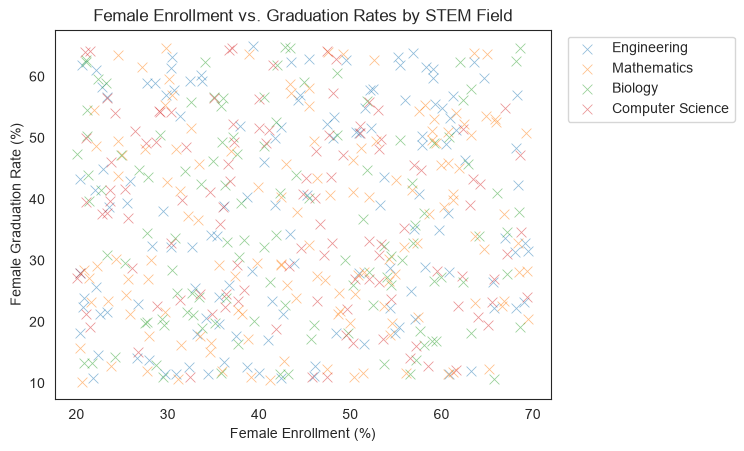

In [82]:
#loop through stem fields column to get individual field names
for field in stem['STEM Fields'].unique():
    field_column_data = stem[stem['STEM Fields'] == field]
    # create scatter plot
    ax = sns.scatterplot(data=field_column_data,
                         x='Female Enrollment (%)',
                         y='Female Graduation Rate (%)',
                         label=field,
                         marker="x",
                         s=50,
                         alpha=0.5)
#place legend outside of plot & change font size 
ax.legend(bbox_to_anchor=(1.02, 1), fontsize=10)
#change title and x/y labels
ax.set_title('Female Enrollment vs. Graduation Rates by STEM Field')
ax.set_xlabel('Female Enrollment (%)')
ax.set_ylabel('Female Graduation Rate (%)')
#change plot background style
sns.set_style("white")
plt.show()

### Part 3

Though creating plots in matplotlib and seaborn may seem relatively similar based on the above examples, as there are similar amounts of code with similar formats used, there are also many differences. In matplotlib, values are provided using .index/ .values. However, in seaborn, values can be directly accessed from Pandas dataframes using x, and y, which is much more intuative. Addionally, seaborn allows for the usage of more built in styles, while matplotlib allows for more individualized customization. For example, to create the gridlines in the matplotlib bar chart, this had to be done manually. However, seaborn has a built in background style called whitegrid, which is able to do this automatically. Overall, while matplotlib allows for more flexibilty, seaborn is more simplified and using it with Pandas data frames feels more instinctive. 

## Conclusions

From creating the above plots, I learned more about global education for women in STEM fields, specifically computer science, mathematics, engineering and biology. The bar plots that I created showed that the gender gap between men and women in STEM fields does not vary greatly by country. The country with the lowest gender gap index, 0.72, was the United States, while Australia and Germany had the highest at 0.76. This means that there is slightly more inequality between men and women in STEM in the United States than in Australia or Germany. A score of 1 would indicate perfect eqality, which none of the countries in this data have. This makes me question whether there are countries that would score a better gender gap index between men and women in STEM fields, or if Germany and Australia have the most equality in the world. The scatter plots that I created explored females enrolled in STEM programs vs. the percentages of females that graduated from their programs by each STEM field, with each point on the graph marking a different country in a different year. There is no noticable trend between any field and the graduation rate/ percentage enrolled. This leads me to believe that these variables may be more dependent upon country/ year than the specific field. 